# 293. Same parts, different order: does a k-mer offset test find rearranged protein pairs?

Two proteins can hold the same parts in a different order: a circular permutation (the
N-terminal part of one protein is the C-terminal part of the other), or two domains swapped.
One local alignment then covers only one of the parts, so the usual pipelines report low
coverage and never flag the pair.

**The test.** Take every k-mer the two proteins share, with its position in each. The
offset of a shared k-mer is its position in B minus its position in A. Colinear proteins
put their shared k-mers on one offset (or a few close ones, after insertions and
deletions). A rearranged pair puts them on two offsets, and the k-mers on the two offsets
come in one order along A and in the reverse order along B. Each offset is one diagonal of a
dot plot, so this test is a dot plot read through k-mers. The idea is old; nothing here
claims it as new. What this notebook measures is how well it works on known rearranged
pairs, at the scale of Swiss-Prot, in three alphabets.

**Question.** From sequence alone, with no alignment and no structure, does the k-mer offset
test find the circular permutations of PermuStructDB and the Pfam domain-order swaps of
Swiss-Prot? At what identity, and how often does it call colinear pairs?

**Decision rule, written before the results.** The k-mer test is a figure for the paper if
its best setting's sensitivity on T1 is at or above that of MMseqs2 with two alignments (C2),
outside the bootstrap 95% interval. The best setting must keep its false call rate on
colinear pairs (N1) at 2% or less. If C2 matches it, the figure still goes in, with the
sentence that MMseqs2 with two alignments does the same and the k-mer version is the one that
runs on sketches.
"Best setting" = the highest T1 sensitivity among settings with an N1 false call rate of 2%
or less. Higher sensitivity is better; a false call rate near the shuffled rate means the
calls are no better than chance.

**Terms.**

* *Setting*: one alphabet, one k and one n_block (the fewest shared k-mers a block needs).
* *Offset*: position in B minus position in A of one shared k-mer occurrence, in residues.
  Offsets are grouped in bins of 3 residues.
* *Block*: a run of adjacent non-empty offset bins holding at least n_block shared k-mer
  occurrences.
* *Called rearranged*: two blocks whose k-mers cover ranges overlapping by at most 10
  residues in A and in B, with the block that starts first along A starting second along B.
* *Chance control*: the same test with B's residues shuffled (composition kept), 10 copies
  per pair, seed 293.
* K-mers seen more than 5 times in either protein are dropped (low complexity) before the
  test. The number dropped is a column of every result table.

**Sets of pairs** (built in section 1):

* **T1**, circular permutations: PermuStructDB pairs of PDB chains, mapped to UniProt with
  SIFTS.
* **T2**, domain-order swaps: Swiss-Prot proteins with the same Pfam families in a different
  order.
* **N1**, colinear pairs: Swiss-Prot proteins with the same Pfam families in the same order,
  drawn to match T2's identity, same count. A call here is a false call.
* **N2**, random Swiss-Prot pairs drawn to match T1 and T2 on the number of shared
  5-mers, so the test cannot win by sharing alone.

**Comparators.** C1: MMseqs2, one alignment per pair (what a standard pipeline sees; it
never calls a rearrangement). C2: MMseqs2 with `--alt-ali 2`, the two best alignments; a
pair is called when they overlap by at most 10 residues in each protein and come in
opposite orders. C3 (Foldseek with a circular-permutation option) was not run: the installed
Foldseek 10.941cd33 lists no such option in `foldseek easy-search -h` (it has `--alt-ali`,
the structural version of C2, not run here). PermuStructDB's own
TM-align scores, with and without its circular-permutation mode, stand in for what
structure sees.

**Tools.** Offset test: `notebooks/kmer_offset_utils.py` (Python, standard library), alphabet
tables of kmerseek's `protein20`, `dayhoff6` and `hp_lehninger2` (the three alphabets
sourmash also sketches), checked against sourmash 4.9.4 in
`scripts/tests/test_kmer_offset_utils.py`. MMseqs2 18.8cc5c. sourmash 4.9.4 with the
branchwater plugin. Every table this notebook reads is made by the scripts in
`scripts/nb293/`; the run order is listed below.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

REPO = Path.cwd().parent
sys.path.insert(0, str(REPO / "notebooks"))
import kmer_offset_utils as ku
import pubfig as pf

DATA = Path(
    os.environ.get("NB293_DIR", "/Users/olga/data/kmer-offset-rearrangements-293")
)
FIG = REPO / "figures"
SWISSPROT = Path("/Users/olga/data/uniprot/uniprot_sprot.2026_03.fasta.gz")
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(60)
pf.use_style()

# One colour per method in every figure of this notebook.
COLOUR = {"kmer": pf.OKABE_ITO["blue"], "C2": pf.OKABE_ITO["vermillion"], "C1": pf.GREY}
ALPHABET_COLOUR = {
    "protein20": pf.OKABE_ITO["blue"],
    "dayhoff6": pf.OKABE_ITO["bluish_green"],
    "hp_lehninger2": pf.OKABE_ITO["reddish_purple"],
}
SET_COLOUR = {
    "T1": pf.OKABE_ITO["blue"],
    "T2": pf.OKABE_ITO["orange"],
    "N1": pf.OKABE_ITO["black"],
    "N2": pf.GREY,
}


def check(ok, msg):
    if not ok:
        raise AssertionError(msg)
    print("ok:", msg)


def pct(x):
    return f"{100 * x:.1f}%"

**Data, and how each table was made.**

Every download, with the URL, release, date, size and md5. The Pfam regions file is 5 GB;
it was filtered to Swiss-Prot rows on Sherlock (job 47824511 resubmitted as 47824998,
`scripts/nb293/filter_pfam_regions_swissprot.sbatch`), and its md5 there matched the
release's `md5_checksums`. The file named `Pfam-A.regions.uniprot.tsv.gz` in the plan does
not exist in Pfam 38.2; `Pfam-A.regions.tsv.gz` is the UniProt-wide file of that release.

Run order (all from the repository root, `D=/Users/olga/data/kmer-offset-rearrangements-293`,
`SP=/Users/olga/data/uniprot/uniprot_sprot.2026_03.fasta.gz`):

1. `scripts/nb293/build_t1_circular_permutations.py $D --accessions-only`, then
   `fetch_uniprot_sequences.py $D/t1_accessions_to_fetch.txt $D/uniprot_sequences.fasta`,
   then `build_t1_circular_permutations.py $D`.
2. `build_t2_n1_pool.py $D $SP`; `run_mmseqs_pairs.py` on `t2_pairs` and on `n1_pool`
   (`--shuffles 0`); `select_n1.py $D`.
3. `run_offset_test.py` on `t1_pairs`, `t2_pairs`, `n1_pairs`; `build_n2_matched_random.py $D $SP
   $D/offset_test_t1.parquet $D/offset_test_t2.parquet`; `run_offset_test.py` on `n2_pairs`.
4. `run_mmseqs_pairs.py` on T1, T2, N1 and N2 (10 shuffled copies each).
5. `sketch_and_search_swissprot.sh $D/scale $SP protein 5 0.2`, then
   `scale_candidates.py $D $SP $D/scale/manysearch.protein.k5.t0.2.csv`.

In [2]:
def md5sum(path):
    import hashlib

    h = hashlib.md5()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


GH = "https://raw.githubusercontent.com/YueHuLab/Circular-permutation-in-PDB/eaa2803c71d76d6f3552db72c8c7e262f90e13f9/"
downloads = [
    (
        "PermuStructDB pairs",
        GH
        + "Dataset%202--TM-Value%20for%20Circular%20permutation%20pairs%20by%20TMalign%20and%20TMalign-CP%20of%20this%20work.txt",
        "GitHub commit eaa2803 (2024-11-28)",
        "2026-10-14",
        DATA
        / "downloads/permustructdb/Dataset 2--TM-Value for Circular permutation pairs by TMalign and TMalign-CP of this work.txt",
    ),
    (
        "PermuStructDB chains",
        GH
        + "Dataset%201--PDB%20ID%20of%20circular%20permutaion%20of%20this%20work.txt",
        "GitHub commit eaa2803 (2024-11-28)",
        "2026-10-14",
        DATA
        / "downloads/permustructdb/Dataset 1--PDB ID of circular permutaion of this work.txt",
    ),
    (
        "SIFTS PDB chain to UniProt",
        "https://ftp.ebi.ac.uk/pub/databases/msd/sifts/flatfiles/tsv/pdb_chain_uniprot.tsv.gz",
        "2026/10/11, PDB 41.26, UniProt 2026.03 (file header)",
        "2026-10-14",
        DATA / "downloads/sifts/pdb_chain_uniprot.tsv.gz",
    ),
    (
        "PDB SEQRES",
        "https://files.wwpdb.org/pub/pdb/derived_data/pdb_seqres.txt.gz",
        "last modified 2026-10-10",
        "2026-10-14",
        DATA / "downloads/pdb_seqres/pdb_seqres.txt.gz",
    ),
    (
        "UniProt sequences of T1",
        "https://rest.uniprot.org/uniprotkb/accessions?accessions=...&format=fasta",
        "UniProt 2026_03 (X-UniProt-Release header)",
        "2026-10-14",
        DATA / "uniprot_sequences.fasta",
    ),
    (
        "Pfam regions, Swiss-Prot rows",
        "https://ftp.ebi.ac.uk/pub/databases/Pfam/current_release/Pfam-A.regions.tsv.gz (5,053,457,363 bytes, md5 f22fb1efefd1e52d6d9c64a8f10003ba), filtered on Sherlock",
        "Pfam 38.2",
        "2026-10-14",
        DATA / "downloads/pfam/Pfam-A.regions.swissprot_2026_03.tsv",
    ),
    (
        "Pfam clans",
        "https://ftp.ebi.ac.uk/pub/databases/Pfam/current_release/Pfam-A.clans.tsv.gz",
        "Pfam 38.2",
        "2026-10-14",
        DATA / "downloads/pfam/Pfam-A.clans.tsv.gz",
    ),
    (
        "Swiss-Prot",
        "local copy, /Users/olga/data/uniprot/uniprot_sprot.2026_03.fasta.gz",
        "UniProt 2026_03",
        "2026-09-08 (file date)",
        SWISSPROT,
    ),
]
manifest = pl.DataFrame(
    [
        {
            "what": w,
            "url": u,
            "release": r,
            "downloaded": d,
            "bytes": p.stat().st_size,
            "md5": md5sum(p),
        }
        for w, u, r, d, p in downloads
    ]
)
print(manifest.select("what", "release", "downloaded", "bytes", "md5"))
for w, u, *_ in downloads:
    print(f"{w}: {u}")

shape: (8, 5)
┌───────────────────────────────┬──────────────────────────────────────────────────────┬────────────────────────┬──────────┬──────────────────────────────────┐
│ what                          ┆ release                                              ┆ downloaded             ┆ bytes    ┆ md5                              │
│ ---                           ┆ ---                                                  ┆ ---                    ┆ ---      ┆ ---                              │
│ str                           ┆ str                                                  ┆ str                    ┆ i64      ┆ str                              │
╞═══════════════════════════════╪══════════════════════════════════════════════════════╪════════════════════════╪══════════╪══════════════════════════════════╡
│ PermuStructDB pairs           ┆ GitHub commit eaa2803 (2024-11-28)                   ┆ 2026-10-14             ┆ 1164856  ┆ f00a7e36bd333171d5b97ac6a600003e │
│ PermuStructDB chains    

## 1. The four sets of pairs (SF1)

**T1.** PermuStructDB (Hu and Huang, bioRxiv 10.1101/2024.08.28.610105; data at
https://github.com/YueHuLab/Circular-permutation-in-PDB, linked from the paper) lists 20,801
circularly permuted pairs of PDB chains over 3,351 chains, found by FoldSeek, MMseqs2 and
TM-align with a circular-permutation mode among 287,081 PDB chains under 800 residues.
Filters, in order, with the reason for each:

1. both chains are in SIFTS;
2. each chain maps to one UniProt entry;
3. the SIFTS segments cover at least 70% of the chain's SEQRES length (SEQRES also holds
   tags, linkers and residues not seen in the structure; the median coverage of mapped
   chains is 0.75);
4. along each chain, its SIFTS segments run in the same order as along its UniProt entry.
   A chain whose segments are out of order is an engineered construct: mostly a circular
   permutation of its own UniProt entry, such as 4zf4_B (GFP, UniProt P42212 residues
   51-237 then 4-50), and in a few cases a fusion of two separate parts (6njh_A, PDE4D
   380-718 then 326-339). The new order is in the construct, not in any UniProt sequence;
5. each UniProt sequence is at least as long as the highest position its chain maps to;
6. the two chains map to different UniProt entries (two chains of one entry give two
   identical UniProt sequences);
7. one pair per pair of UniProt entries (the chain pair with the highest TM-align score in
   circular-permutation mode is kept).

**T2.** Pfam 38.2 regions on Swiss-Prot 2026_03. Pfam 38 annotates the sequences of the
UniProtKB reference proteomes (release 2025_03, Pfam's `relnotes.txt`), so only 317,364 of
the 575,748 Swiss-Prot proteins have Pfam regions in its files. The others, concanavalin A
(P02866) among them, cannot enter T2 or N1, and step 6 cannot label them as T2. Proteins whose Pfam sequence md5 matches the
current Swiss-Prot sequence, with no two Pfam domains overlapping by more than 10 residues
(nested domains such as PF07687 inside PF01546 have no order), and at least two distinct
families. Two proteins with the same multiset of families form a T2 pair when their orders
differ, also at the level of Pfam clans (EF-hand families of clan CL0220 swap labels between
proteins, which is not a change of order), and at least one pair of families comes in
opposite orders. At most 5 pairs per family multiset are tested, seed 293.

**N1** draws pairs with the same families in the same order to match T2's identity in
10-point bins. **N2** draws random pairs from 20,000 random Swiss-Prot proteins to match T1
and T2 together on the number of shared protein20 5-mers, in bins of
floor(log2(n + 1)).

In [3]:
t1_counts = pl.read_csv(DATA / "t1_filter_counts.tsv", separator="\t")
t2_counts = pl.read_csv(DATA / "t2_counts.tsv", separator="\t")
n1_bins = pl.read_csv(DATA / "n1_bin_counts.tsv", separator="\t")
n2_bins = pl.read_csv(DATA / "n2_bin_counts.tsv", separator="\t")
print(t1_counts)
print(t2_counts)
print("N1, identity bins (10-point bins of the best MMseqs2 alignment's identity):")
print(n1_bins)
print("N2, shared 5-mer bins (floor(log2(n + 1))):")
print(n2_bins)

offset, mm = ku.load_results(DATA)
real = offset.filter(pl.col("copy") == -1)
n_pairs = (
    real.filter(
        (pl.col("alphabet") == "protein20")
        & (pl.col("ksize") == 5)
        & (pl.col("n_block") == 3)
    )
    .group_by("pair_set")
    .len()
    .sort("pair_set")
)
print(n_pairs)
N_T1 = n_pairs.filter(pl.col("pair_set") == "T1")["len"][0]
check(
    N_T1 == t1_counts["n_pairs"][-1], f"T1 has {N_T1} pairs, as the filter table says"
)
check(
    n_pairs.filter(pl.col("pair_set") == "N1")["len"][0]
    == n_pairs.filter(pl.col("pair_set") == "T2")["len"][0],
    "N1 has as many pairs as T2",
)

t1 = pl.read_parquet(DATA / "t1_pairs.parquet")
print(
    f"T1: {t1.height} pairs over {pl.concat([t1['accession_a'], t1['accession_b']]).n_unique()} UniProt entries"
)
print("UniProt entries in the most T1 pairs:")
print(pl.concat([t1["accession_a"], t1["accession_b"]]).value_counts(sort=True).head(8))

clans = pl.read_csv(
    DATA / "downloads/pfam/Pfam-A.clans.tsv.gz",
    separator="\t",
    has_header=False,
    new_columns=["family", "clan", "clan_id", "family_id", "description"],
    quote_char=None,
)
fam_name = dict(clans.select("family", "family_id").iter_rows())
swaps = (
    pl.read_parquet(DATA / "t2_order_pairs.parquet")
    .explode("swapped_family_pairs")
    .group_by("swapped_family_pairs")
    .agg(
        pl.col("n_t2_pairs").sum(),
        pl.col("family_multiset").n_unique().alias("n_family_groups"),
    )
    .sort("n_t2_pairs", "swapped_family_pairs", descending=[True, False])
    .with_columns(
        pl.col("swapped_family_pairs")
        .map_elements(
            lambda s: " / ".join(fam_name.get(f, f) for f in s.split("/")), pl.Utf8
        )
        .alias("names")
    )
)
print(
    "Most common pairs of Pfam families in opposite orders in T2 (all 1,525 pairs, not only the tested sample):"
)
print(swaps.head(12))

shape: (8, 2)
┌────────────────────────────────┬─────────┐
│ filter                         ┆ n_pairs │
│ ---                            ┆ ---     │
│ str                            ┆ i64     │
╞════════════════════════════════╪═════════╡
│ f0_permustructdb_pairs         ┆ 20801   │
│ f1_both_in_sifts               ┆ 14328   │
│ f2_one_accession_each          ┆ 13046   │
│ f3_sifts_covers_chain          ┆ 11142   │
│ f4_chain_order_matches_uniprot ┆ 8393    │
│ f5_uniprot_covers_chain        ┆ 8393    │
│ f6_different_accessions        ┆ 1424    │
│ f7_unique_accession_pairs      ┆ 140     │
└────────────────────────────────┴─────────┘
shape: (11, 2)
┌───────────────────────────────────────────────┬─────────┐
│ step                                          ┆ n       │
│ ---                                           ┆ ---     │
│ str                                           ┆ i64     │
╞═══════════════════════════════════════════════╪═════════╡
│ pfam_rows_swissprot                    

shape: (4, 2)
┌──────────┬─────┐
│ pair_set ┆ len │
│ ---      ┆ --- │
│ str      ┆ u32 │
╞══════════╪═════╡
│ N1       ┆ 230 │
│ N2       ┆ 369 │
│ T1       ┆ 140 │
│ T2       ┆ 230 │
└──────────┴─────┘
ok: T1 has 140 pairs, as the filter table says
ok: N1 has as many pairs as T2
T1: 140 pairs over 181 UniProt entries
UniProt entries in the most T1 pairs:
shape: (8, 2)
┌─────────────┬───────┐
│ accession_a ┆ count │
│ ---         ┆ ---   │
│ str         ┆ u32   │
╞═════════════╪═══════╡
│ P02866      ┆ 19    │
│ P42088      ┆ 8     │
│ Q0ZNA6      ┆ 8     │
│ P42212      ┆ 7     │
│ Q39890      ┆ 7     │
│ Q12959      ┆ 6     │
│ P0DP23      ┆ 6     │
│ P00282      ┆ 5     │
└─────────────┴───────┘
Most common pairs of Pfam families in opposite orders in T2 (all 1,525 pairs, not only the tested sample):
shape: (12, 4)
┌──────────────────────┬────────────┬─────────────────┬─────────────────────────────────┐
│ swapped_family_pairs ┆ n_t2_pairs ┆ n_family_groups ┆ names                  

Identity of the best MMseqs2 alignment (C1) by set (median, and pairs with no alignment at E <= 1e-3):
shape: (4, 4)
┌──────────┬─────────────────┬────────────────┬─────┐
│ pair_set ┆ median_identity ┆ n_no_alignment ┆ len │
│ ---      ┆ ---             ┆ ---            ┆ --- │
│ str      ┆ f64             ┆ u32            ┆ u32 │
╞══════════╪═════════════════╪════════════════╪═════╡
│ N1       ┆ 0.364           ┆ 33             ┆ 230 │
│ N2       ┆ 0.6135          ┆ 141            ┆ 369 │
│ T1       ┆ 0.84            ┆ 0              ┆ 140 │
│ T2       ┆ 0.348           ┆ 33             ┆ 230 │
└──────────┴─────────────────┴────────────────┴─────┘
Shared protein20 5-mer occurrences by set:
shape: (4, 4)
┌──────────┬────────┬─────────────────┬─────┐
│ pair_set ┆ median ┆ 90th percentile ┆ len │
│ ---      ┆ ---    ┆ ---             ┆ --- │
│ str      ┆ f64    ┆ f64             ┆ u32 │
╞══════════╪════════╪═════════════════╪═════╡
│ N1       ┆ 6.0    ┆ 48.0            ┆ 230 │
│ N2      

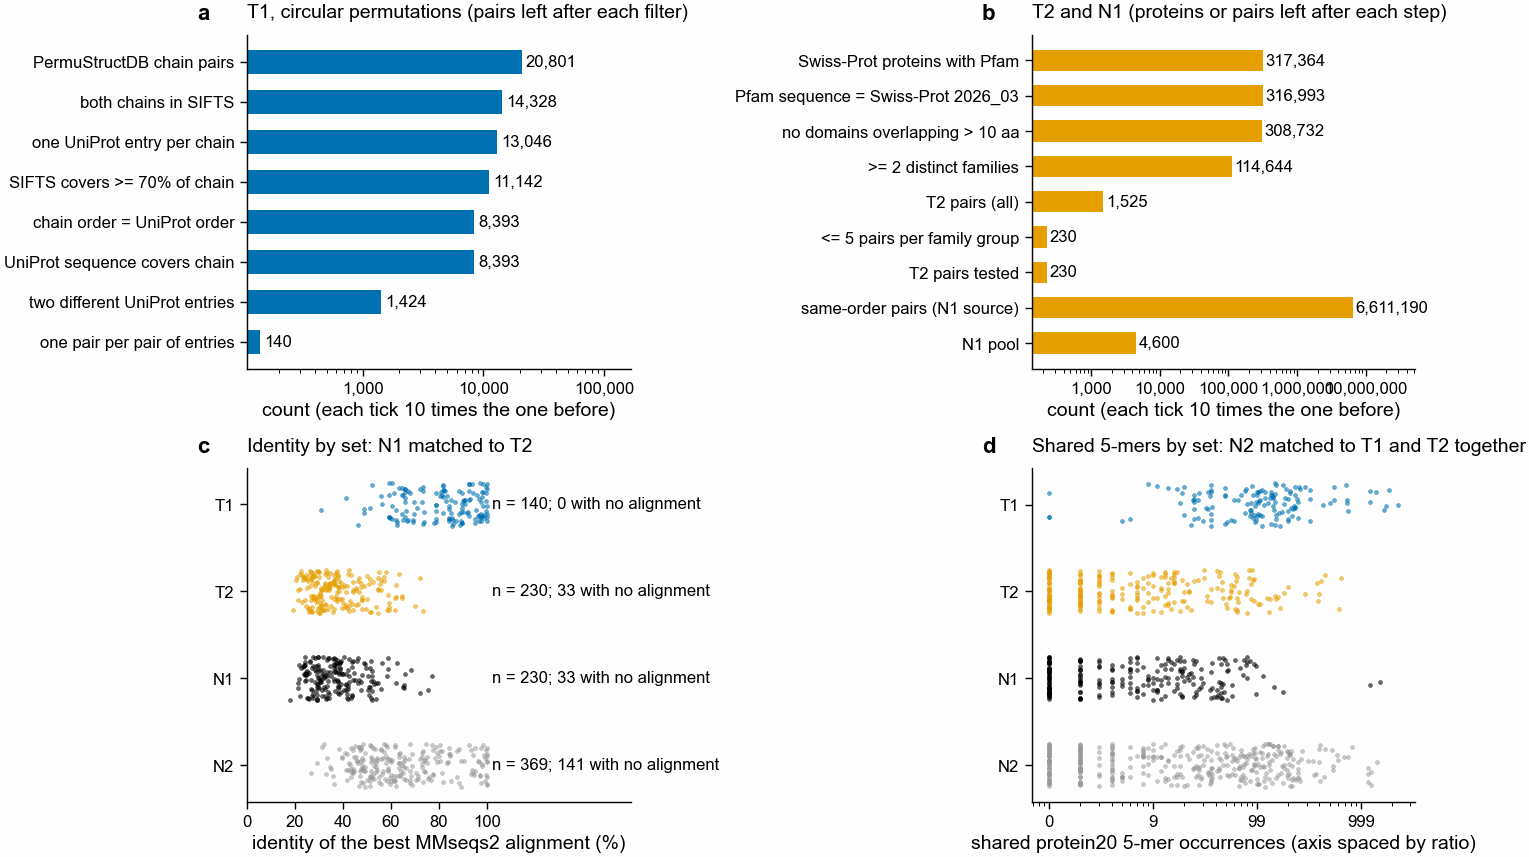

In [4]:
ident = mm.filter(pl.col("copy") == -1).select("pair_set", "identity")
shared = real.filter(
    (pl.col("alphabet") == "protein20")
    & (pl.col("ksize") == 5)
    & (pl.col("n_block") == 3)
).select("pair_set", "n_shared_kmer_hits")
print(
    "Identity of the best MMseqs2 alignment (C1) by set (median, and pairs with no alignment at E <= 1e-3):"
)
print(
    ident.group_by("pair_set")
    .agg(
        pl.col("identity").median().alias("median_identity"),
        pl.col("identity").is_null().sum().alias("n_no_alignment"),
        pl.len(),
    )
    .sort("pair_set")
)
print("Shared protein20 5-mer occurrences by set:")
print(
    shared.group_by("pair_set")
    .agg(
        pl.col("n_shared_kmer_hits").median().alias("median"),
        pl.col("n_shared_kmer_hits").quantile(0.9).alias("90th percentile"),
        pl.len(),
    )
    .sort("pair_set")
)


def draw_sf1():
    fig = plt.figure(
        figsize=(pf.TWO_COLUMN_MM * pf.MM, 110 * pf.MM), layout="constrained"
    )
    gs = fig.add_gridspec(2, 2)
    axes = [
        fig.add_subplot(gs[0, 0]),
        fig.add_subplot(gs[0, 1]),
        fig.add_subplot(gs[1, 0]),
        fig.add_subplot(gs[1, 1]),
    ]
    labels_t1 = {
        "f0_permustructdb_pairs": "PermuStructDB chain pairs",
        "f1_both_in_sifts": "both chains in SIFTS",
        "f2_one_accession_each": "one UniProt entry per chain",
        "f3_sifts_covers_chain": "SIFTS covers >= 70% of chain",
        "f4_chain_order_matches_uniprot": "chain order = UniProt order",
        "f5_uniprot_covers_chain": "UniProt sequence covers chain",
        "f6_different_accessions": "two different UniProt entries",
        "f7_unique_accession_pairs": "one pair per pair of entries",
    }
    for ax, df, col, lab, colour, title in [
        (
            axes[0],
            t1_counts,
            "n_pairs",
            labels_t1,
            SET_COLOUR["T1"],
            "T1, circular permutations (pairs left after each filter)",
        ),
        (
            axes[1],
            t2_counts.filter(pl.col("step").str.contains("pairs|proteins")),
            "n",
            {
                "proteins_with_pfam": "Swiss-Prot proteins with Pfam",
                "proteins_md5_matches_swissprot_2026_03": "Pfam sequence = Swiss-Prot 2026_03",
                "proteins_no_domain_overlap_over_10aa": "no domains overlapping > 10 aa",
                "proteins_with_2plus_distinct_families": ">= 2 distinct families",
                "t2_pairs_all": "T2 pairs (all)",
                "t2_pairs_after_per_group_cap": "<= 5 pairs per family group",
                "t2_pairs_sampled": "T2 pairs tested",
                "n1_same_order_pairs_all": "same-order pairs (N1 source)",
                "n1_pool_pairs": "N1 pool",
            },
            SET_COLOUR["T2"],
            "T2 and N1 (proteins or pairs left after each step)",
        ),
    ]:
        names = [lab.get(s, s) for s in df[df.columns[0]].to_list()]
        vals = df[col].to_list()
        y = np.arange(len(vals))[::-1]
        ax.barh(y, vals, color=colour, height=0.6)
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.set_yticks(y, names)
        for yi, v in zip(y, vals):
            ax.text(v * 1.08, yi, f"{v:,}", va="center", fontsize=6)
        ax.set_xlim(right=max(vals) * 8)
        ax.set_xlabel("count (each tick 10 times the one before)")
        ax.set_title(title, loc="left")
    # c: identity by set
    ax = axes[2]
    order = ["T1", "T2", "N1", "N2"]
    rng = np.random.default_rng(293)
    for i, s in enumerate(order):
        v = ident.filter(pl.col("pair_set") == s)["identity"]
        n_none = v.is_null().sum()
        vals = v.drop_nulls().to_numpy() * 100
        ax.scatter(
            vals,
            i + rng.uniform(-0.25, 0.25, len(vals)),
            s=3,
            color=SET_COLOUR[s],
            alpha=0.6,
            linewidths=0,
        )
        ax.text(
            102, i, f"n = {len(v)}; {n_none} with no alignment", va="center", fontsize=6
        )
    ax.set_yticks(range(len(order)), order)
    ax.set_xlim(0, 160)
    ax.set_xticks([0, 20, 40, 60, 80, 100])
    ax.invert_yaxis()
    ax.set_xlabel("identity of the best MMseqs2 alignment (%)")
    ax.set_title("Identity by set: N1 matched to T2", loc="left")
    # d: shared k-mers
    ax = axes[3]
    for i, s in enumerate(order):
        vals = shared.filter(pl.col("pair_set") == s)["n_shared_kmer_hits"].to_numpy()
        ax.scatter(
            vals + 1,
            i + rng.uniform(-0.25, 0.25, len(vals)),
            s=3,
            color=SET_COLOUR[s],
            alpha=0.6,
            linewidths=0,
        )
    ax.set_xscale("log")
    ax.set_xticks([1, 10, 100, 1000], ["0", "9", "99", "999"])
    ax.set_yticks(range(len(order)), order)
    ax.invert_yaxis()
    ax.set_xlabel("shared protein20 5-mer occurrences (axis spaced by ratio)")
    ax.set_title("Shared 5-mers by set: N2 matched to T1 and T2 together", loc="left")
    for ax, letter in zip(axes, "abcd"):
        pf.panel_label(ax, letter)
    return fig


fig = draw_sf1()
pf.save(fig, FIG / "293_sf1_pair_sets_PermuStructDB_SwissProt_Pfam38_2")

## 2. Hero example: a natural circular permutation between two legume lectins (step 7)

A = UniProt P42088, lectin of *Leucomphalos mildbraedii* (PDB 2fmd_A). B = UniProt P08902,
lectin alpha chain of *Macropsychanthus grandiflorus* (PDB 1dgl_A). Concanavalin A and its
relatives in the Diocleinae are circularly permuted against other legume lectins (the mature
protein is ligated after processing); PermuStructDB lists this pair with a TM-score of 0.50
from TM-align and 0.98 from TM-align in circular-permutation mode. The setting shown is the
best setting chosen in section 3. Coordinates are 1-based and inclusive.

In [5]:
HERO_A, HERO_B = "P42088", "P08902"
BEST = dict(
    alphabet="protein20", ksize=5, n_block=5
)  # checked against the rule in section 3
seqs_t1 = ku.read_fasta(DATA / "uniprot_sequences.fasta")
names_t1 = {}
for line in open(DATA / "uniprot_sequences.fasta"):
    if line.startswith(">"):
        acc = line.split("|")[1]
        names_t1[acc] = line.split(" ", 1)[1].split(" OX=")[0].strip()
seq_a, seq_b = seqs_t1[HERO_A], seqs_t1[HERO_B]
hero = real.filter(
    (pl.col("accession_a") == HERO_A)
    & (pl.col("accession_b") == HERO_B)
    & (pl.col("alphabet") == BEST["alphabet"])
    & (pl.col("ksize") == BEST["ksize"])
    & (pl.col("n_block") == BEST["n_block"])
).row(0, named=True)
check(hero["called"], "the hero pair is called by the best setting")
print(f"A {HERO_A}: {names_t1[HERO_A]}")
print(f"B {HERO_B}: {names_t1[HERO_B]}")
print(
    f"PDB chains {hero['chain_a']} and {hero['chain_b']}; TM-align {hero['tm_align']:.2f}, TM-align circular-permutation mode {hero['tm_align_cp']:.2f}"
)
blocks = []
for t in ["block1", "block2"]:
    blocks.append(
        {
            k: hero[f"{t}_{k}"]
            for k in [
                "a_start",
                "a_end",
                "b_start",
                "b_end",
                "n_kmers",
                "offset_median",
                "identical",
                "compared",
            ]
        }
    )
    b = blocks[-1]
    print(
        f"{t}: A {b['a_start'] + 1}-{b['a_end']}, B {b['b_start'] + 1}-{b['b_end']}, "
        f"{b['n_kmers']} shared 5-mers, median offset {b['offset_median']:+d}, gapless identity {b['identical']} of {b['compared']}"
    )
print()
print(
    ku.format_sequence_with_blocks(
        f"A {HERO_A}",
        seq_a,
        [
            (blocks[0]["a_start"], blocks[0]["a_end"], "1"),
            (blocks[1]["a_start"], blocks[1]["a_end"], "2"),
        ],
    )
)
print()
print(
    ku.format_sequence_with_blocks(
        f"B {HERO_B}",
        seq_b,
        [
            (blocks[0]["b_start"], blocks[0]["b_end"], "1"),
            (blocks[1]["b_start"], blocks[1]["b_end"], "2"),
        ],
    )
)
hits, n_dropped = ku.shared_kmer_hits(seq_a, seq_b, BEST["alphabet"], BEST["ksize"])
hist = ku.offset_histogram(hits)
print(
    f"\nOffset histogram ({len(hits)} shared 5-mer occurrences, {n_dropped} 5-mers dropped as low complexity); bin start (residues): count"
)
print(", ".join(f"{k:+d}: {v}" for k, v in hist.items()))
for i, b in enumerate(blocks, 1):
    print(f"\nBlock {i}, gapless comparison at offset {b['offset_median']:+d}:")
    print(ku.format_block_comparison("A", seq_a, "B", seq_b, b))

ok: the hero pair is called by the best setting
A P42088: Lectin OS=Leucomphalos mildbraedii
B P08902: Lectin alpha chain OS=Macropsychanthus grandiflorus
PDB chains 2fmd_A and 1dgl_A; TM-align 0.50, TM-align circular-permutation mode 0.98
block1: A 47-111, B 169-233, 12 shared 5-mers, median offset +122, gapless identity 42 of 65
block2: A 131-217, B 12-98, 12 shared 5-mers, median offset -119, gapless identity 59 of 87

A P42088 (240 aa)
    1 ANSVCFTFTDFESGQQDLIFQGDASVGSNKALQLTKVDSKGNPQGGSVGRALYTAPIRLW 60
                                                    11111111111111
   61 QSSSLVASFETTFTFSISQGSSTPAAALTFFIASPDTKIPSGSGGRLLGLFGSSNNAGSD 120
      111111111111111111111111111111111111111111111111111         
  121 NGVVAVEFDTYPNTDIGDPNYRHIGIDVNSIRSKAASKWDWQNGKTATAHISYNSASKRL 180
                22222222222222222222222222222222222222222222222222
  181 SVVSSYPNSSPVVVSFDVELNNVGPPDVRVGFSATTGQYTQTNNILAWSFRSSLMGYQAN 240
      2222222222222222222222222222222222222                       

B P0

C1, what a standard pipeline sees: one alignment, A 123-234 against B 4-115, E = 3.0e-43, identity 0.66, covering 47.3% of the shorter protein. Not flagged.
A   123 VVAVEFDTYPNTDIGDPNYRHIGIDVNSIRSKAASKWDWQNGKTATAHISYNSASKRLSV 182
         |||| | ||||||||||| |||||  |||||    |  | ||  | ||||||  |||| 
B     4 IVAVELDSYPNTDIGDPNYPHIGIDIKSIRSKSTARWNMQTGKVGTVHISYNSVAKRLSA 63

A   183 VSSYPNSSPVVVSFDVELNNVGPPDVRVGFSATTGQYTQTNNILAWSFRSSL 234
        | ||  ||   || || |||| |  |||| ||||| |  || || ||| | |
B    64 VVSYSGSSSTTVSYDVDLNNVLPEWVRVGLSATTGLYKETNTILSWSFTSKL 115

74 of 112 aligned columns identical

C2's second alignment: A 2-115 against B 124-237, E = 4.3e-33
A     2 NSVCFTFTDFESGQQDLIFQGDASVGSNKALQLTKVDSKGNPQGGSVGRALYTAPIRLWQ 61
        ||  | |  |     ||| ||||   |   | |||| | | ||| ||||||  ||   | 
B   124 NSLHFSFHKFSQNPKDLILQGDAFTDSDGNLELTKVSSSGDPQGNSVGRALFYAPVHIWE 183

A    62 SSSLVASFETTFTFSISQGSSTPAAALTFFIASPDTKIPSGSGGRLLGLFGSSN 115
        ||  ||||  |||| |      ||   |||||  || ||||||||||

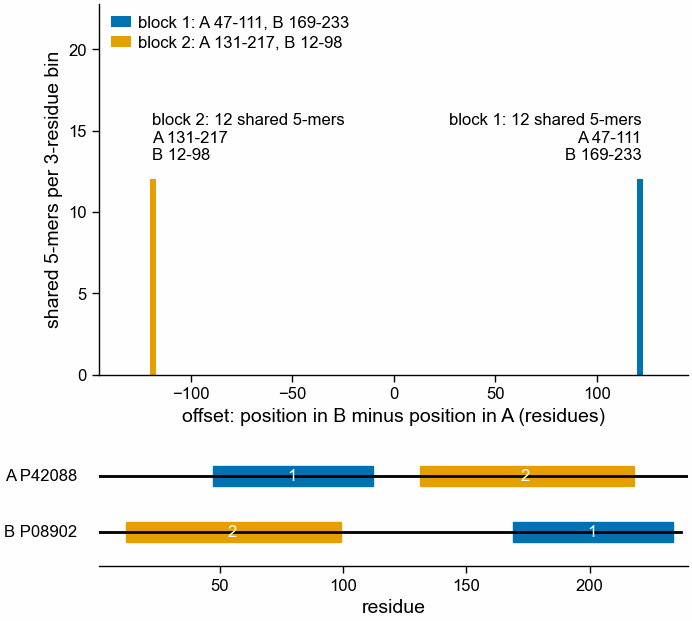

In [6]:
mm_raw_t1 = pl.read_parquet(DATA / "mmseqs_t1.parquet").filter(
    (pl.col("copy") == -1)
    & (pl.col("accession_a") == HERO_A)
    & (pl.col("accession_b") == HERO_B)
)
c1 = mm_raw_t1.filter(pl.col("method") == "C1").row(0, named=True)
cov = (c1["qend"] - c1["qstart"] + 1) / min(c1["qlen"], c1["tlen"])
print(
    f"C1, what a standard pipeline sees: one alignment, A {c1['qstart']}-{c1['qend']} against B {c1['tstart']}-{c1['tend']}, "
    f"E = {c1['evalue']:.1e}, identity {c1['fident']:.2f}, covering {pct(cov)} of the shorter protein. Not flagged."
)
print(
    ku.format_local_alignment(
        "A", "B", c1["qaln"], c1["taln"], c1["qstart"], c1["tstart"]
    )
)
c2 = mm_raw_t1.filter((pl.col("method") == "C2") & (pl.col("alignment_rank") == 1)).row(
    0, named=True
)
print(
    f"\nC2's second alignment: A {c2['qstart']}-{c2['qend']} against B {c2['tstart']}-{c2['tend']}, E = {c2['evalue']:.1e}"
)
print(
    ku.format_local_alignment(
        "A", "B", c2["qaln"], c2["taln"], c2["qstart"], c2["tstart"]
    )
)
c2_hero = mm.filter(
    (pl.col("copy") == -1)
    & (pl.col("accession_a") == HERO_A)
    & (pl.col("accession_b") == HERO_B)
)["c2_called"][0]
print(f"\nC2 calls this pair: {c2_hero}")


def draw_hero(ax_hist, ax_prot):
    xs = np.array(list(hist.keys()))
    ys = np.array(list(hist.values()))
    in_blocks = sum(b["n_kmers"] for b in blocks)
    outside = len(hits) - in_blocks
    ax_hist.bar(
        xs + ku.BIN_WIDTH / 2,
        ys,
        width=ku.BIN_WIDTH,
        color=pf.GREY,
        label=f"shared 5-mers outside a block ({outside})" if outside else None,
    )
    block_colour = [pf.OKABE_ITO["blue"], pf.OKABE_ITO["orange"]]
    for i, b in enumerate(blocks):
        bins = {}
        for i0, j in hits:
            off = j - i0
            if b["a_start"] <= i0 < b["a_end"] and b["b_start"] <= j < b["b_end"]:
                key = (off // ku.BIN_WIDTH) * ku.BIN_WIDTH
                bins[key] = bins.get(key, 0) + 1
        ax_hist.bar(
            np.array(list(bins)) + ku.BIN_WIDTH / 2,
            list(bins.values()),
            width=ku.BIN_WIDTH,
            color=block_colour[i],
            label=f"block {i + 1}: A {b['a_start'] + 1}-{b['a_end']}, B {b['b_start'] + 1}-{b['b_end']}",
        )
        ax_hist.annotate(
            f"block {i + 1}: {b['n_kmers']} shared 5-mers\nA {b['a_start'] + 1}-{b['a_end']}\nB {b['b_start'] + 1}-{b['b_end']}",
            xy=(b["offset_median"], max(bins.values())),
            xytext=(0, 6),
            textcoords="offset points",
            ha="left" if b["offset_median"] < 0 else "right",
            va="bottom",
            fontsize=6,
        )
    ax_hist.set_xlabel("offset: position in B minus position in A (residues)")
    ax_hist.set_ylabel("shared 5-mers per 3-residue bin")
    ax_hist.set_ylim(0, max(ys) * 1.9)
    span = max(abs(x) for x in xs) + 25
    ax_hist.set_xlim(-span, span)
    ax_hist.legend(loc="upper left", frameon=False)
    # Proteins as a line with boxes for the blocks (A above, B below).
    for row, (name, seq, side) in enumerate(
        [(f"A {HERO_A}", seq_a, "a"), (f"B {HERO_B}", seq_b, "b")]
    ):
        y = 1 - row
        ax_prot.plot([1, len(seq)], [y, y], color="black", lw=1)
        for i, b in enumerate(blocks):
            s, e = b[f"{side}_start"] + 1, b[f"{side}_end"]
            ax_prot.add_patch(
                plt.Rectangle((s, y - 0.18), e - s + 1, 0.36, color=block_colour[i])
            )
            ax_prot.text(
                (s + e) / 2,
                y,
                str(i + 1),
                ha="center",
                va="center",
                fontsize=6,
                color="white",
            )
        ax_prot.text(-8, y, name, ha="right", va="center", fontsize=6)
    ax_prot.set_ylim(-0.6, 1.6)
    ax_prot.set_xlim(1, max(len(seq_a), len(seq_b)))
    ax_prot.set_yticks([])
    ax_prot.spines["left"].set_visible(False)
    ax_prot.set_xlabel("residue")


fig, (ax1, ax2) = pf.figure(pf.ONE_COLUMN_MM, 80, nrows=2, height_ratios=[3, 1])
draw_hero(ax1, ax2)
pf.save(
    fig,
    FIG
    / f"293_hero_offset_histogram_P42088_P08902_{BEST['alphabet']}_k{BEST['ksize']}",
)

## 3. Every setting (step 5, SF2)

For every setting: sensitivity on T1 and T2, false call rate on N1 and N2, and the call rate
on the shuffled copies, each with a bootstrap 95% interval over pairs (2,000 resamples).
Two stricter sensitivities count a call only when it sits in the right place:

* T1, *call inside the chains' region*: each block (or alignment) lies at least half inside
  the UniProt range the PDB chain covers, in both proteins;
* T2, *call on the same family*: each block (or alignment) lies at least half on a Pfam
  domain of one family in A and on a domain of the same family in B.

Many T1 UniProt entries hold several copies of a domain (PDZ domains in DLG1 to DLG4,
spectrin repeats) while the PDB chain covers one. A call between two different copies is a
rearrangement of repeats, not the permutation PermuStructDB found. One more call outside the
region, BRD4 (O60885) against BRD2 (P25440), pairs two serine- and glutamate-rich stretches
(`SSSESESSSESSS` with `SSSESSSEESSSESSS`) that the low-complexity filter (a 5-mer seen more
than 5 times) did not remove.

Two limits of the call rule were found when testing it. A permutation whose two parts share
more than 10 residues at the junction is missed. And the C2 count with no overlap allowed
(printed below the table) is fragile: it moves when MMseqs2's alignment ends move by one or
two residues (12 here, 9 with `mmseqs search --exhaustive-search`). Only the 10-residue
version is used.

shape: (29, 10)
┌─────────────────────────┬────────────────┬────────────────────────┬────────────────┬────────────────────────┬───────────────┬───────────────┬──────────────────┬──────────────────┬──────────────────┐
│ method                  ┆ t1_sensitivity ┆ t1_sensitivity_in_chai ┆ t2_sensitivity ┆ t2_sensitivity_on_same ┆ n1_false_rate ┆ n2_false_rate ┆ shuffled_rate_t1 ┆ shuffled_rate_t2 ┆ shuffled_rate_n1 │
│ ---                     ┆ ---            ┆ n_region               ┆ ---            ┆ _family                ┆ ---           ┆ ---           ┆ ---              ┆ ---              ┆ ---              │
│ str                     ┆ f64            ┆ ---                    ┆ f64            ┆ ---                    ┆ f64           ┆ f64           ┆ f64              ┆ f64              ┆ f64              │
│                         ┆                ┆ f64                    ┆                ┆ f64                    ┆               ┆               ┆                  ┆                  

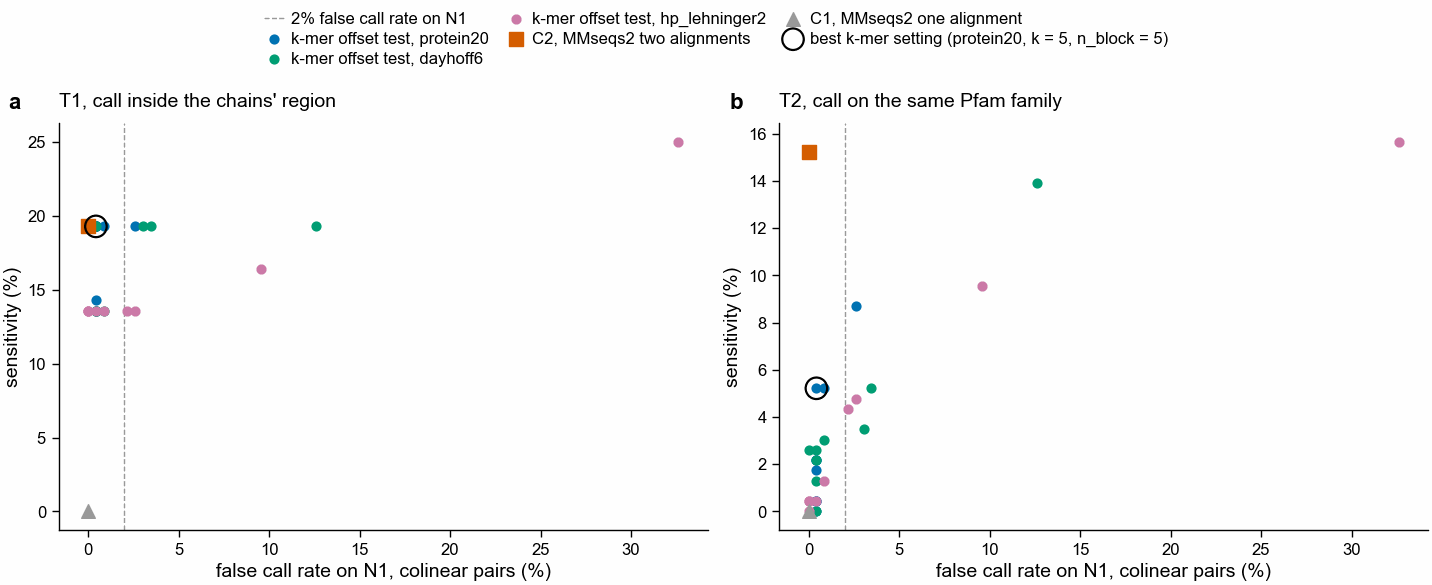

In [7]:
table = ku.settings_table(offset, mm)
show = [
    "method",
    "t1_sensitivity",
    "t1_sensitivity_in_chain_region",
    "t2_sensitivity",
    "t2_sensitivity_on_same_family",
    "n1_false_rate",
    "n2_false_rate",
    "shuffled_rate_t1",
    "shuffled_rate_t2",
    "shuffled_rate_n1",
]
print(table.select(show).with_columns(pl.selectors.float().round(3)))
table.write_csv(DATA / "293_sf2_settings_table.tsv", separator="\t")
print(f"full table with intervals and n: {DATA / '293_sf2_settings_table.tsv'}")

kmer = table.filter(pl.col("alphabet").is_not_null())
eligible = kmer.filter(pl.col("n1_false_rate") <= 0.02).sort(
    ["t1_sensitivity", "n1_false_rate", "alphabet", "ksize", "n_block"],
    descending=[True, False, False, False, False],
)
best = eligible.row(0, named=True)
print(f"\nbest setting by the rule: {best['method']}")
check(
    (best["alphabet"], best["ksize"], best["n_block"])
    == (BEST["alphabet"], BEST["ksize"], BEST["n_block"]),
    "the hero section used the best setting",
)
ties = eligible.filter(pl.col("t1_sensitivity") == best["t1_sensitivity"])
print(f"settings tied at the top T1 sensitivity: {ties.height}")
c2row = table.filter(pl.col("method").str.starts_with("C2")).row(0, named=True)
t1_mm = mm.filter((pl.col("copy") == -1) & (pl.col("pair_set") == "T1"))
print(
    f"C2 on T1: {t1_mm['c2_called'].sum()} of {t1_mm.height} with up to {ku.MAX_OVERLAP} residues of overlap allowed, "
    f"{t1_mm['c2_called_no_overlap'].sum()} with none"
)
c1row = table.filter(pl.col("method").str.starts_with("C1")).row(0, named=True)


def draw_sf2():
    fig, axes = pf.figure(pf.TWO_COLUMN_MM, 75, ncols=2)
    for ax, col, title in [
        (
            axes[0],
            "t1_sensitivity_in_chain_region",
            "T1, call inside the chains' region",
        ),
        (axes[1], "t2_sensitivity_on_same_family", "T2, call on the same Pfam family"),
    ]:
        ax.axvline(2, color=pf.GREY, lw=0.5, ls="--", label="2% false call rate on N1")
        for alphabet, colour in ALPHABET_COLOUR.items():
            sub = kmer.filter(pl.col("alphabet") == alphabet)
            ax.scatter(
                100 * sub["n1_false_rate"],
                100 * sub[col],
                s=10,
                color=colour,
                marker="o",
                label=f"k-mer offset test, {alphabet}",
                zorder=3,
            )
        ax.scatter(
            100 * c2row["n1_false_rate"],
            100 * c2row[col],
            s=24,
            color=COLOUR["C2"],
            marker="s",
            label="C2, MMseqs2 two alignments",
            zorder=4,
        )
        ax.scatter(
            100 * c1row["n1_false_rate"],
            100 * c1row[col],
            s=24,
            color=COLOUR["C1"],
            marker="^",
            label="C1, MMseqs2 one alignment",
            zorder=4,
        )
        ax.scatter(
            100 * best["n1_false_rate"],
            100 * best[col],
            s=60,
            facecolors="none",
            edgecolors="black",
            lw=0.8,
            zorder=5,
            label=f"best k-mer setting ({best['alphabet']}, k = {best['ksize']}, n_block = {best['n_block']})",
        )
        ax.set_xlabel("false call rate on N1, colinear pairs (%)")
        ax.set_ylabel("sensitivity (%)")
        ax.set_title(title, loc="left")
    pf.shared_legend(fig, ncol=3)
    for ax, letter in zip(axes, "ab"):
        pf.panel_label(ax, letter)
    return fig


print(
    kmer.select(
        "alphabet",
        "ksize",
        "n_block",
        "n1_false_rate",
        "t1_sensitivity_in_chain_region",
        "t2_sensitivity_on_same_family",
    ).with_columns(pl.selectors.float().round(3))
)
fig = draw_sf2()
pf.save(fig, FIG / "293_sf2_every_setting_T1_T2_vs_N1_PermuStructDB_SwissProt")

## 4. Sensitivity by identity (step 5)

Identity is that of the best MMseqs2 alignment (C1) of the real pair. Bins as planned:
under 30%, 30 to 50%, 50 to 90%, over 90%. T1 has no pair under 30% and 5 at 30 to 50%:
PermuStructDB's pairs are mostly close homologs at the sequence level.

T1, call inside the chains' region:
shape: (3, 11)
┌──────────┬──────────────┬─────┬───────┬─────────┬─────────┬───────────────┬───────┬───────┬───────┬─────────────┐
│ pair_set ┆ identity_bin ┆ n   ┆ kmer  ┆ kmer_lo ┆ kmer_hi ┆ kmer_n_called ┆ c2    ┆ c2_lo ┆ c2_hi ┆ c2_n_called │
│ ---      ┆ ---          ┆ --- ┆ ---   ┆ ---     ┆ ---     ┆ ---           ┆ ---   ┆ ---   ┆ ---   ┆ ---         │
│ str      ┆ str          ┆ i64 ┆ f64   ┆ f64     ┆ f64     ┆ i64           ┆ f64   ┆ f64   ┆ f64   ┆ i64         │
╞══════════╪══════════════╪═════╪═══════╪═════════╪═════════╪═══════════════╪═══════╪═══════╪═══════╪═════════════╡
│ T1       ┆ 30 to 50%    ┆ 5   ┆ 0.0   ┆ 0.0     ┆ 0.0     ┆ 0             ┆ 0.0   ┆ 0.0   ┆ 0.0   ┆ 0           │
│ T1       ┆ 50 to 90%    ┆ 88  ┆ 0.239 ┆ 0.148   ┆ 0.33    ┆ 21            ┆ 0.239 ┆ 0.148 ┆ 0.33  ┆ 21          │
│ T1       ┆ over 90%     ┆ 47  ┆ 0.128 ┆ 0.043   ┆ 0.234   ┆ 6             ┆ 0.128 ┆ 0.043 ┆ 0.234 ┆ 6           │
└──────────┴─────────

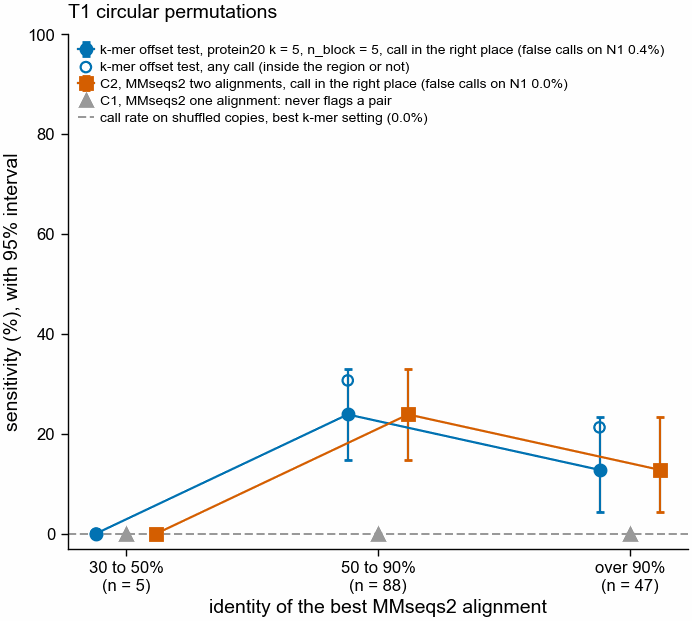

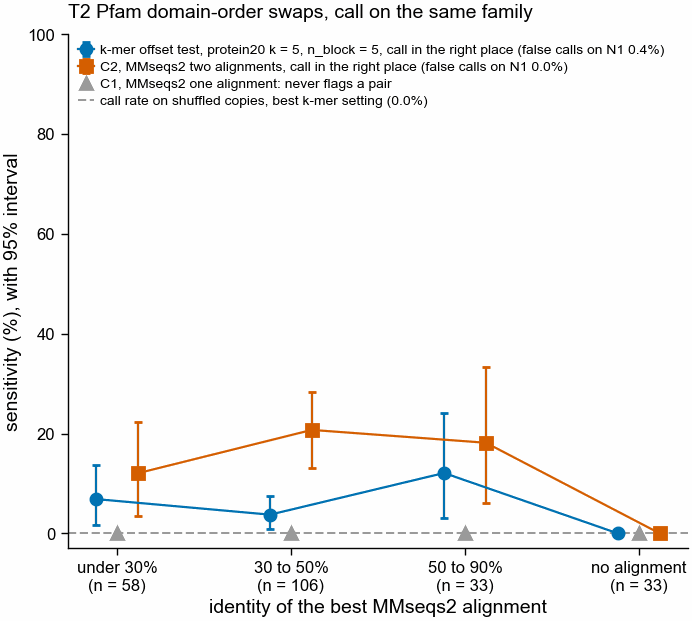

In [8]:
def by_identity(df_kmer, df_mm, pair_set, kmer_col, c2_col):
    rows = []
    for label in ku.IDENTITY_BIN_LABELS + ["no alignment"]:
        k = df_kmer.filter(
            (pl.col("pair_set") == pair_set) & (pl.col("identity_bin") == label)
        )[kmer_col]
        c = df_mm.filter(
            (pl.col("pair_set") == pair_set) & (pl.col("identity_bin") == label)
        )[c2_col]
        if k.len() == 0:
            continue
        km, klo, khi, n = ku.rate_with_ci(k.to_list())
        cm, clo, chi, _ = ku.rate_with_ci(c.to_list())
        rows.append(
            {
                "pair_set": pair_set,
                "identity_bin": label,
                "n": n,
                "kmer": km,
                "kmer_lo": klo,
                "kmer_hi": khi,
                "kmer_n_called": int(k.sum()),
                "c2": cm,
                "c2_lo": clo,
                "c2_hi": chi,
                "c2_n_called": int(c.sum()),
            }
        )
    return pl.DataFrame(rows)


best_rows = real.filter(
    (pl.col("alphabet") == BEST["alphabet"])
    & (pl.col("ksize") == BEST["ksize"])
    & (pl.col("n_block") == BEST["n_block"])
)
mm_real = mm.filter(pl.col("copy") == -1)
ident_t1 = by_identity(
    best_rows, mm_real, "T1", "called_in_chain_region", "c2_called_in_chain_region"
)
ident_t1_any = by_identity(best_rows, mm_real, "T1", "called", "c2_called")
ident_t2 = by_identity(
    best_rows, mm_real, "T2", "called_on_same_family", "c2_called_on_same_family"
)
print("T1, call inside the chains' region:")
print(ident_t1.with_columns(pl.selectors.float().round(3)))
print("T1, any call:")
print(ident_t1_any.with_columns(pl.selectors.float().round(3)))
print("T2, call on the same family:")
print(ident_t2.with_columns(pl.selectors.float().round(3)))

cov = mm_real.filter(pl.col("pair_set") == "T1").select(
    "accession_a",
    "accession_b",
    "c1_coverage_of_shorter",
    "c2_called",
    "c2_called_in_chain_region",
)
split = (
    best_rows.filter(pl.col("pair_set") == "T1")
    .join(cov, on=["accession_a", "accession_b"])
    .with_columns(
        pl.when(pl.col("c1_coverage_of_shorter") > 0.95)
        .then(pl.lit("one alignment covers > 95% (colinear in UniProt)"))
        .otherwise(pl.lit("one alignment covers <= 95%"))
        .alias("t1_part")
    )
)
print("T1 split by how much of the shorter protein one MMseqs2 alignment covers:")
print(
    split.group_by("t1_part")
    .agg(
        pl.len(),
        pl.col("called").sum().alias("kmer_any_call"),
        pl.col("called_in_chain_region").sum().alias("kmer_in_region"),
        pl.col("c2_called").sum().alias("c2_any_call"),
        pl.col("c2_called_in_chain_region").sum().alias("c2_in_region"),
    )
    .sort("t1_part")
)


def draw_identity(ax, df, df_any, shuffled_rate, n1_kmer, n1_c2, title):
    x = np.arange(df.height)
    off = 0.12
    ax.errorbar(
        x - off,
        100 * df["kmer"],
        yerr=[100 * (df["kmer"] - df["kmer_lo"]), 100 * (df["kmer_hi"] - df["kmer"])],
        fmt="o-",
        color=COLOUR["kmer"],
        ms=4,
        capsize=1.5,
        lw=0.8,
        label=f"k-mer offset test, {best['alphabet']} k = {best['ksize']}, n_block = {best['n_block']}, call in the right place (false calls on N1 {pct(n1_kmer)})",
        zorder=3,
    )
    if df_any is not None:
        ax.scatter(
            x - off,
            100 * df_any["kmer"],
            s=14,
            facecolors="none",
            edgecolors=COLOUR["kmer"],
            lw=0.8,
            zorder=3,
            label="k-mer offset test, any call (inside the region or not)",
        )
    ax.errorbar(
        x + off,
        100 * df["c2"],
        yerr=[100 * (df["c2"] - df["c2_lo"]), 100 * (df["c2_hi"] - df["c2"])],
        fmt="s-",
        color=COLOUR["C2"],
        ms=4,
        capsize=1.5,
        lw=0.8,
        label=f"C2, MMseqs2 two alignments, call in the right place (false calls on N1 {pct(n1_c2)})",
        zorder=3,
    )
    ax.plot(
        x,
        np.zeros(len(x)),
        "^",
        color=COLOUR["C1"],
        ms=4,
        zorder=4,
        label="C1, MMseqs2 one alignment: never flags a pair",
    )
    ax.axhline(
        100 * shuffled_rate,
        color=pf.GREY,
        lw=0.8,
        ls="--",
        zorder=1,
        label=f"call rate on shuffled copies, best k-mer setting ({pct(shuffled_rate)})",
    )
    ax.set_xticks(x, [f"{b}\n(n = {n})" for b, n in zip(df["identity_bin"], df["n"])])
    ax.set_xlabel("identity of the best MMseqs2 alignment")
    ax.set_ylabel("sensitivity (%), with 95% interval")
    ax.set_ylim(-3, 100)
    ax.set_title(title, loc="left")


def identity_legend(ax):
    handles, labels = ax.get_legend_handles_labels()
    rank = lambda lab: (
        0
        if lab.startswith("k-mer offset test, " + best["alphabet"])
        else (
            1
            if lab.startswith("k-mer offset test, any")
            else 2 if lab.startswith("C2") else 3 if lab.startswith("C1") else 4
        )
    )
    order = sorted(range(len(labels)), key=lambda i: rank(labels[i]))
    ax.legend(
        [handles[i] for i in order],
        [labels[i] for i in order],
        loc="upper left",
        frameon=False,
        fontsize=5,
    )


fig, ax = pf.figure(pf.ONE_COLUMN_MM, 80)
draw_identity(
    ax,
    ident_t1,
    ident_t1_any,
    best["shuffled_rate_t1"],
    best["n1_false_rate"],
    c2row["n1_false_rate"],
    "T1 circular permutations",
)
identity_legend(ax)
pf.save(fig, FIG / "293_sensitivity_by_identity_T1_PermuStructDB")

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 80)
draw_identity(
    ax,
    ident_t2,
    None,
    best["shuffled_rate_t2"],
    best["n1_false_rate"],
    c2row["n1_false_rate"],
    "T2 Pfam domain-order swaps, call on the same family",
)
identity_legend(ax)
pf.save(fig, FIG / "293_sensitivity_by_identity_T2_SwissProt_Pfam38_2")

## 5. Scale on Swiss-Prot (step 6, SF3)

Not all of Swiss-Prot against itself. Every Swiss-Prot protein was sketched with sourmash in
the best setting's alphabet and k (`protein`, k = 5, scaled = 1, so every 5-mer is kept),
indexed, and searched against the index. Candidate pairs: query containment of at least 0.2
(at least 20% of the query's distinct 5-mers are in the match). Of those, the pairs whose
single MMseqs2 alignment covers less than half of the shorter protein went to the offset
test. A called pair is labelled T1 (the UniProt pair is a T1 pair), T2 (its two Pfam
architectures are a T2 pair of orders) or neither. Only the pairs in neither could be new,
and they are candidates, not findings, until a structure agrees.

In [9]:
SCALE = DATA / "scale"
SETTING = f"{BEST['alphabet']}_k{BEST['ksize']}_n{BEST['n_block']}"
times = pl.read_csv(SCALE / "stage_times.tsv", separator="\t")
sm_times = []
for stage in ["manysketch", "index", "manysearch"]:
    txt = (SCALE / f"{stage}.time").read_text()
    real_s = float([l for l in txt.splitlines() if " real " in l][-1].split()[0])
    rss = int(
        [l for l in txt.splitlines() if "maximum resident set size" in l][-1].split()[0]
    )
    sm_times.append(
        {"stage": f"sourmash {stage}", "seconds": real_s, "peak_memory_gb": rss / 1e9}
    )
print(pl.DataFrame(sm_times))
print(times)
scale = pl.read_parquet(SCALE / f"candidates_{SETTING}.parquet")
cand_all = pl.read_parquet(SCALE / "candidates_all.parquet")
called = scale.filter(pl.col("called"))
neither = called.filter(~pl.col("in_t1") & ~pl.col("in_t2"))
summary = pl.DataFrame(
    [
        {"step": "candidate pairs, containment >= 0.2", "n": cand_all.height},
        {
            "step": "single MMseqs2 alignment covers < 50% of the shorter",
            "n": scale.height,
        },
        {"step": "called by the offset test", "n": called.height},
        {"step": "called, in T1", "n": int(called["in_t1"].sum())},
        {"step": "called, in T2", "n": int(called["in_t2"].sum())},
        {"step": "called, in neither", "n": neither.height},
    ]
)
print(summary)
sp_acc = set(ku.read_fasta(SWISSPROT))
n_t1_sprot = t1.filter(
    pl.col("accession_a").is_in(list(sp_acc))
    & pl.col("accession_b").is_in(list(sp_acc))
).height
print(
    f"T1 pairs with both proteins in Swiss-Prot (the most step 6 can find): {n_t1_sprot} of {t1.height}"
)

shape: (3, 3)
┌─────────────────────┬─────────┬────────────────┐
│ stage               ┆ seconds ┆ peak_memory_gb │
│ ---                 ┆ ---     ┆ ---            │
│ str                 ┆ f64     ┆ f64            │
╞═════════════════════╪═════════╪════════════════╡
│ sourmash manysketch ┆ 307.87  ┆ 1.080312       │
│ sourmash index      ┆ 2162.81 ┆ 4.948148       │
│ sourmash manysearch ┆ 305.33  ┆ 30.457184      │
└─────────────────────┴─────────┴────────────────┘
shape: (3, 3)
┌────────────────────────────────────────┬────────────┬──────────┐
│ stage                                  ┆ seconds    ┆ n_pairs  │
│ ---                                    ┆ ---        ┆ ---      │
│ str                                    ┆ f64        ┆ i64      │
╞════════════════════════════════════════╪════════════╪══════════╡
│ read_and_deduplicate_candidates        ┆ 12.145789  ┆ 11101174 │
│ mmseqs2_c1_on_candidates               ┆ 784.494773 ┆ 11101174 │
│ offset_test_on_low_coverage_candidates ┆ 1

T1 pairs with both proteins in Swiss-Prot (the most step 6 can find): 89 of 140


In [10]:
seqs_sp = ku.read_fasta(SWISSPROT)
arch = pl.read_parquet(DATA / "swissprot_architectures.parquet")
# Every Pfam 38.2 domain on each Swiss-Prot protein (not only the proteins kept for T2).
regions_all = (
    pl.read_csv(
        DATA / "downloads/pfam/Pfam-A.regions.swissprot_2026_03.tsv",
        separator="\t",
        schema_overrides={"pfamseq_acc": pl.Utf8, "pfamA_acc": pl.Utf8},
    )
    .sort("pfamseq_acc", "seq_start")
    .group_by("pfamseq_acc", maintain_order=True)
    .agg("pfamA_acc", "seq_start", "seq_end")
)
arch_of = {a: (f, s, e) for a, f, s, e in regions_all.iter_rows()}
sp_names = {}
import gzip

with gzip.open(SWISSPROT, "rt") as fh:
    for line in fh:
        if line.startswith(">"):
            sp_names[line.split("|")[1]] = (
                line.split(" ", 1)[1].split(" OX=")[0].strip()
            )


def architecture_text(acc):
    if acc not in arch_of:
        return "no Pfam 38.2 regions (not in the UniProtKB reference proteomes Pfam 38 annotates)"
    f, s, e = arch_of[acc]
    return ", ".join(f"{fam_name.get(x, x)} {a}-{b}" for x, a, b in zip(f, s, e))


top10 = (
    neither.with_columns(
        pl.min_horizontal("block1_n_kmers", "block2_n_kmers").alias(
            "weaker_block_kmers"
        )
    )
    .sort(
        ["weaker_block_kmers", "accession_a", "accession_b"],
        descending=[True, False, False],
    )
    .head(10)
)
print(
    top10.select(
        "accession_a",
        "accession_b",
        "containment",
        "c1_coverage_of_shorter",
        "c1_identity",
        "block1_n_kmers",
        "block2_n_kmers",
        "block1_identical",
        "block1_compared",
        "block2_identical",
        "block2_compared",
    )
)
for r in top10.iter_rows(named=True):
    a, b = r["accession_a"], r["accession_b"]
    print("=" * 100)
    print(f"A {a}: {sp_names.get(a)}\n   Pfam: {architecture_text(a)}")
    print(f"B {b}: {sp_names.get(b)}\n   Pfam: {architecture_text(b)}")
    for t in ["block1", "block2"]:
        blk = {k: r[f"{t}_{k}"] for k in ["a_start", "a_end", "offset_median"]}
        print(
            f"{t}: A {r[t + '_a_start'] + 1}-{r[t + '_a_end']}, B {r[t + '_b_start'] + 1}-{r[t + '_b_end']}, {r[t + '_n_kmers']} shared 5-mers"
        )
        print(ku.format_block_comparison("A", seqs_sp[a], "B", seqs_sp[b], blk))

shape: (10, 11)
┌─────────────┬─────────────┬─────────────┬────────────────────────┬─────────────┬────────────────┬────────────────┬──────────────────┬─────────────────┬──────────────────┬─────────────────┐
│ accession_a ┆ accession_b ┆ containment ┆ c1_coverage_of_shorter ┆ c1_identity ┆ block1_n_kmers ┆ block2_n_kmers ┆ block1_identical ┆ block1_compared ┆ block2_identical ┆ block2_compared │
│ ---         ┆ ---         ┆ ---         ┆ ---                    ┆ ---         ┆ ---            ┆ ---            ┆ ---              ┆ ---             ┆ ---              ┆ ---             │
│ str         ┆ str         ┆ f64         ┆ f64                    ┆ f64         ┆ i64            ┆ i64            ┆ i64              ┆ i64             ┆ i64              ┆ i64             │
╞═════════════╪═════════════╪═════════════╪════════════════════════╪═════════════╪════════════════╪════════════════╪══════════════════╪═════════════════╪══════════════════╪═════════════════╡
│ Q51817      ┆ Q51845      ┆

850 called pairs in neither set: 678 with no MMseqs2 alignment at E <= 1e-3; median length of the shorter protein 37 aa; 603 with the shorter protein under 100 aa
Most common names of protein A among them:
shape: (15, 3)
┌──────────────────────────────────────────────────────┬─────┬───────────────────────┐
│ name_a                                               ┆ len ┆ median_shorter_length │
│ ---                                                  ┆ --- ┆ ---                   │
│ str                                                  ┆ u32 ┆ f64                   │
╞══════════════════════════════════════════════════════╪═════╪═══════════════════════╡
│ Drosulfakinins                                       ┆ 160 ┆ 11.0                  │
│ Sperm protamine P1                                   ┆ 64  ┆ 50.0                  │
│ Protamine TP16                                       ┆ 49  ┆ 33.0                  │
│ Protamine TP17                                       ┆ 49  ┆ 33.0                

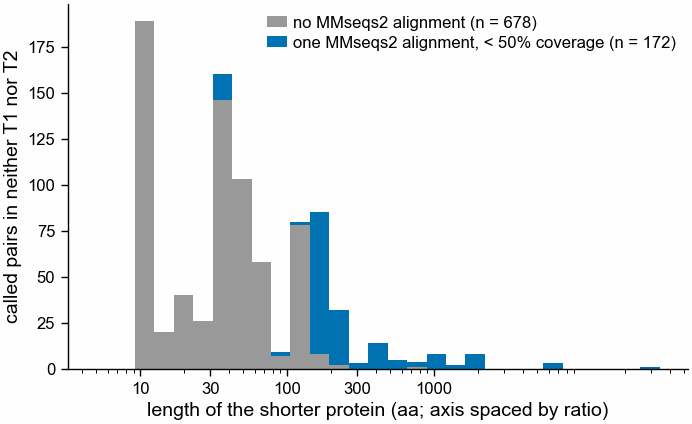

In [11]:
nb = neither.with_columns(
    pl.min_horizontal(
        pl.col("accession_a").replace_strict({a: len(x) for a, x in seqs_sp.items()}),
        pl.col("accession_b").replace_strict({a: len(x) for a, x in seqs_sp.items()}),
    ).alias("shorter_length"),
    pl.col("accession_a")
    .replace_strict(sp_names, default="")
    .str.replace(r" OS=.*", "")
    .alias("name_a"),
)
print(
    f"{neither.height} called pairs in neither set: {nb['c1_identity'].is_null().sum()} with no MMseqs2 alignment at E <= 1e-3; "
    f"median length of the shorter protein {nb['shorter_length'].median():.0f} aa; "
    f"{(nb['shorter_length'] < 100).sum()} with the shorter protein under 100 aa"
)
print("Most common names of protein A among them:")
print(
    nb.group_by("name_a")
    .agg(pl.len(), pl.col("shorter_length").median().alias("median_shorter_length"))
    .sort(["len", "name_a"], descending=[True, False])
    .head(15)
)


def draw_neither_lengths():
    fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
    has = nb.filter(pl.col("c1_identity").is_not_null())["shorter_length"].to_numpy()
    none = nb.filter(pl.col("c1_identity").is_null())["shorter_length"].to_numpy()
    bins = np.logspace(
        np.log10(5), np.log10(max(nb["shorter_length"].max(), 10) + 1), 30
    )
    ax.hist(
        [none, has],
        bins=bins,
        stacked=True,
        color=[pf.GREY, COLOUR["kmer"]],
        label=[
            f"no MMseqs2 alignment (n = {len(none)})",
            f"one MMseqs2 alignment, < 50% coverage (n = {len(has)})",
        ],
    )
    ax.set_xscale("log")
    ax.set_xticks([10, 30, 100, 300, 1000], ["10", "30", "100", "300", "1000"])
    ax.set_xlabel("length of the shorter protein (aa; axis spaced by ratio)")
    ax.set_ylabel("called pairs in neither T1 nor T2")
    ax.legend(loc="upper right", frameon=False)
    return fig


fig = draw_neither_lengths()
pf.save(fig, FIG / f"293_step6_called_pairs_in_neither_by_length_SwissProt_{SETTING}")

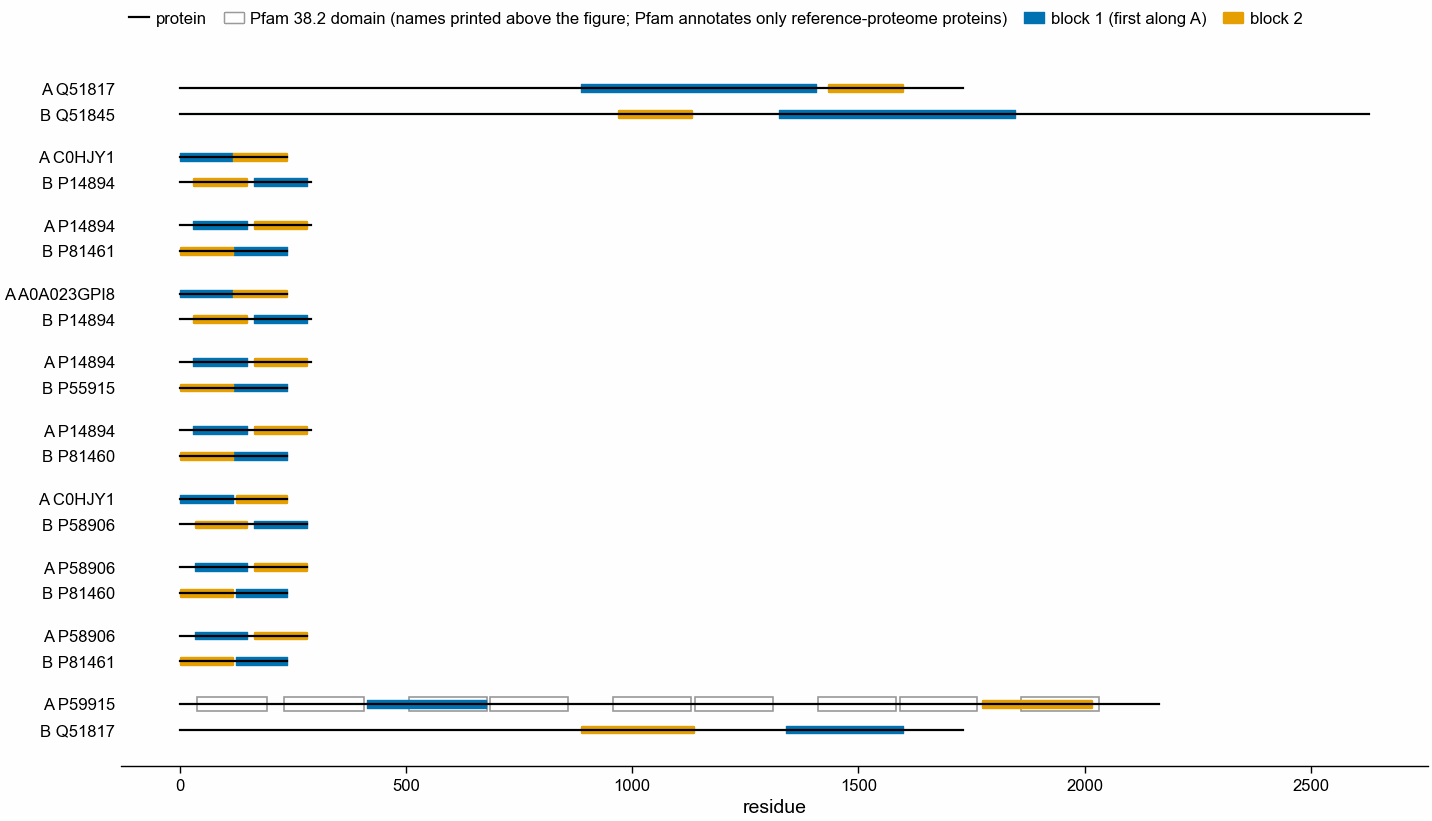

In [12]:
def draw_sf3():
    n = top10.height
    fig, ax = pf.figure(pf.TWO_COLUMN_MM, max(40, 9 * n + 15))
    block_colour = [pf.OKABE_ITO["blue"], pf.OKABE_ITO["orange"]]
    y = 0
    labels = []
    for r in top10.iter_rows(named=True):
        for side, acc in [("a", r["accession_a"]), ("b", r["accession_b"])]:
            L = len(seqs_sp[acc])
            ax.plot([1, L], [y, y], color="black", lw=0.8)
            if acc in arch_of:
                for fam, s, e in zip(*arch_of[acc]):
                    ax.add_patch(
                        plt.Rectangle(
                            (s, y - 0.32),
                            e - s + 1,
                            0.64,
                            facecolor="none",
                            edgecolor=pf.GREY,
                            lw=0.6,
                        )
                    )
            for i, t in enumerate(["block1", "block2"]):
                s, e = r[f"{t}_{side}_start"] + 1, r[f"{t}_{side}_end"]
                ax.add_patch(
                    plt.Rectangle((s, y - 0.18), e - s + 1, 0.36, color=block_colour[i])
                )
            labels.append((y, f"{'A' if side == 'a' else 'B'} {acc}"))
            y -= 1.2
        y -= 0.8
    ax.set_yticks([p for p, _ in labels], [t for _, t in labels])
    ax.set_xlabel("residue")
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    handles = [
        plt.Line2D([], [], color="black", lw=0.8, label="protein"),
        plt.Rectangle(
            (0, 0),
            1,
            1,
            facecolor="none",
            edgecolor=pf.GREY,
            label="Pfam 38.2 domain (names printed above the figure; Pfam annotates only reference-proteome proteins)",
        ),
        plt.Rectangle(
            (0, 0), 1, 1, color=block_colour[0], label="block 1 (first along A)"
        ),
        plt.Rectangle((0, 0), 1, 1, color=block_colour[1], label="block 2"),
    ]
    fig.legend(handles=handles, loc="outside upper center", ncol=4, frameon=False)
    return fig


if top10.height:
    fig = draw_sf3()
    pf.save(fig, FIG / f"293_sf3_top10_new_candidates_SwissProt_{SETTING}")

## 6. Main figure

**a**, the hero pair's offset histogram (shared 5-mers per 3-residue offset bin) with the two
blocks, and the two proteins drawn as lines with the blocks as boxes. **b**, sensitivity on T1
by identity, a call counted only when it lies inside the region the two PDB chains cover
(filled) or any call (open), with the false call rate on N1 in the legend and the call rate
on shuffled copies as a dashed line.

On 140 circularly permuted pairs with sequences, the offset test (protein20, k = 5, n_block = 5) finds 26.4% [19.3%, 33.6%] at a false rate of 0.4% on colinear pairs; MMseqs2 with two alignments finds 19.3% [12.9%, 25.7%]; a single alignment flags none.
Counting only calls inside the region the two PDB chains cover: offset test 19.3% [12.9%, 25.7%], MMseqs2 with two alignments 19.3% [12.9%, 25.7%].
Two alignments from MMseqs2 find the same pairs; the k-mer test adds nothing beyond a dot plot. The k-mer version is the one that runs on sketches.
shape: (3, 11)
┌──────────┬──────────────┬─────┬───────┬─────────┬─────────┬───────────────┬───────┬───────┬───────┬─────────────┐
│ pair_set ┆ identity_bin ┆ n   ┆ kmer  ┆ kmer_lo ┆ kmer_hi ┆ kmer_n_called ┆ c2    ┆ c2_lo ┆ c2_hi ┆ c2_n_called │
│ ---      ┆ ---          ┆ --- ┆ ---   ┆ ---     ┆ ---     ┆ ---           ┆ ---   ┆ ---   ┆ ---   ┆ ---         │
│ str      ┆ str          ┆ i64 ┆ f64   ┆ f64     ┆ f64     ┆ i64           ┆ f64   ┆ f

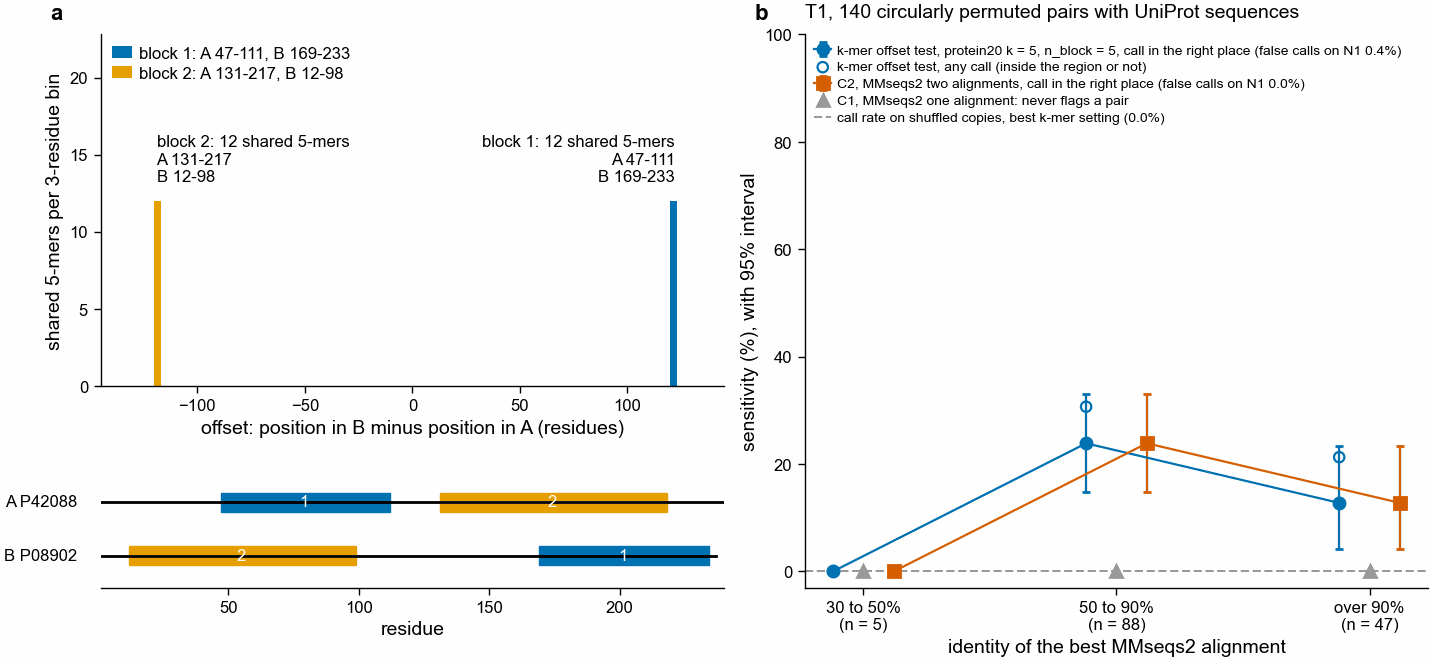

In [13]:
def main_figure():
    fig = plt.figure(
        figsize=(pf.TWO_COLUMN_MM * pf.MM, 85 * pf.MM), layout="constrained"
    )
    gs = fig.add_gridspec(2, 2, height_ratios=[3, 1], width_ratios=[1, 1])
    ax_hist, ax_prot = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])
    ax_id = fig.add_subplot(gs[:, 1])
    draw_hero(ax_hist, ax_prot)
    draw_identity(
        ax_id,
        ident_t1,
        ident_t1_any,
        best["shuffled_rate_t1"],
        best["n1_false_rate"],
        c2row["n1_false_rate"],
        f"T1, {N_T1} circularly permuted pairs with UniProt sequences",
    )
    identity_legend(ax_id)
    pf.panel_label(ax_hist, "a")
    pf.panel_label(ax_id, "b")
    return fig


def verdict(tbl):
    b = (
        tbl.filter(pl.col("alphabet").is_not_null() & (pl.col("n1_false_rate") <= 0.02))
        .sort(
            ["t1_sensitivity", "n1_false_rate", "alphabet", "ksize", "n_block"],
            descending=[True, False, False, False, False],
        )
        .row(0, named=True)
    )
    c2 = tbl.filter(pl.col("method").str.starts_with("C2")).row(0, named=True)
    setting = f"{b['alphabet']}, k = {b['ksize']}, n_block = {b['n_block']}"
    fmt = lambda r, c: f"{pct(r[c])} [{pct(r[c + '_lo'])}, {pct(r[c + '_hi'])}]"
    lines = [
        f"On {b['t1_sensitivity_n']} circularly permuted pairs with sequences, the offset test ({setting}) finds "
        f"{fmt(b, 't1_sensitivity')} at a false rate of {pct(b['n1_false_rate'])} on colinear pairs; MMseqs2 with two "
        f"alignments finds {fmt(c2, 't1_sensitivity')}; a single alignment flags none.",
        f"Counting only calls inside the region the two PDB chains cover: offset test {fmt(b, 't1_sensitivity_in_chain_region')}, "
        f"MMseqs2 with two alignments {fmt(c2, 't1_sensitivity_in_chain_region')}.",
    ]
    alive = (
        b["t1_sensitivity_in_chain_region_lo"] > c2["t1_sensitivity_in_chain_region_hi"]
    ) and b["n1_false_rate"] <= 0.02
    if alive:
        lines.append(
            "The k-mer offset test finds rearrangements a single alignment never reports, from sequence alone."
        )
    else:
        lines.append(
            "Two alignments from MMseqs2 find the same pairs; the k-mer test adds nothing beyond a dot plot. "
            "The k-mer version is the one that runs on sketches."
        )
    return alive, lines


fig = main_figure()
pf.save(fig, FIG / f"293_main_kmer_offset_test_PermuStructDB_T1_{SETTING}")
alive, lines = verdict(table)
for line in lines:
    print(line)
print(ident_t1.with_columns(pl.selectors.float().round(3)))

## 7. Summary and conclusions

**Verdict (decision rule from the top of the notebook): MMseqs2 with two alignments matches the
k-mer offset test.** On T1, counting only calls inside the region the two PDB chains cover,
the best k-mer setting (protein20, k = 5, n_block = 5) and C2 call the same 27 of 140 pairs,
19.3% [12.9%, 25.7%] each. The k-mer test's higher raw rate, 26.4% [19.3%, 33.6%], comes
from 10 calls outside that region: 9 between different copies of a repeated domain (PDZ
domains of DLG proteins, spectrin repeats) and 1 between low-complexity serine and glutamate
stretches of BRD4 and BRD2. The figure goes in with the sentence that MMseqs2 with two
alignments does the same, and that the k-mer version is the one that runs on sketches.

**Claims the data supports**

* A single MMseqs2 alignment never flags a rearranged pair; on the hero lectin pair it
  covers 47.3% of the shorter protein.
* The k-mer offset test finds circular permutations from sequence alone: 27 of 140 T1 pairs
  at the right place, 27 of the 50 T1 pairs whose UniProt sequences are not colinear (where
  one alignment covers 95% or less of the shorter protein), with 1 false call in 230
  colinear N1 pairs, 2 in 369 random N2 pairs, and 0 in 1,400 shuffled copies of T1.
* MMseqs2 with two alignments calls the same 27 T1 pairs, with no false call on N1, N2 or
  any shuffled copy.
* On Pfam domain-order swaps (T2), C2 finds more than the k-mer test: 35 against 12 of 230
  pairs with both parts on the same Pfam family, and at least as many in every identity bin,
  including under 30% identity (7 against 4 of 58).
* Reduced alphabets do not help here. dayhoff6 and hp_lehninger2 reach T1 sensitivity no
  higher than protein20 inside the 2% false call limit (best: dayhoff6 k = 10, n_block = 5,
  22.1%; hp_lehninger2 k = 20, n_block = 5, 15.7%). hp_lehninger2 at k = 15, n_block = 3 calls
  17% of shuffled T1 copies and 54% of shuffled T2 copies: its calls are mostly chance.
* The sketch route scales: sketching all 575,748 Swiss-Prot proteins took 5 minutes, the
  index 36 minutes and the all-against-all search 5 minutes (30 GB of memory) on the laptop,
  giving 11,101,174 candidate pairs; MMseqs2 on all of them took 13 minutes and the offset
  test on the 586,917 with low single-alignment coverage took 14 seconds.

**Claims the data does not support**

* That the k-mer test finds rearrangements MMseqs2 with two alignments misses. On T1 the
  call sets inside the chains' region are identical; on T2 C2 finds more.
* Anything below 30% identity for circular permutations: T1 has no pair under 30% identity
  and 5 pairs at 30 to 50%, none called by either method.
* Any new rearranged protein from Swiss-Prot. Of the 853 pairs called at scale, 3 are T1
  pairs (all concanavalin A, P02866), none is a T2 pair (only proteins with Pfam 38.2 regions
  can be), and the 850 others are mostly short
  repetitive peptides: 678 have no MMseqs2 alignment at all, and the shorter protein's median
  length is 37 aa. The ten strongest are
  concanavalin A-type lectins of *Canavalia* (the known permutation between a lectin
  precursor and the mature, ligated lectin) and gingipain and hemagglutinin A repeats of
  *Porphyromonas gingivalis*. None was checked against a structure (C3 was not run), so none
  is a finding.
* That PermuStructDB's 20,801 pairs are a sequence-level truth set: only 140 distinct UniProt
  pairs remain, and 90 of those are colinear in UniProt (one alignment covers more than 95%
  of the shorter protein). In those 90 the permutation PermuStructDB found is not in the
  UniProt sequences.

**Figures**

* Main figure: `figures/293_main_kmer_offset_test_PermuStructDB_T1_protein20_k5_n5.pdf`
  (a, hero offset histogram and the two proteins; b, T1 sensitivity by identity).
* SF1, the four sets: `figures/293_sf1_pair_sets_PermuStructDB_SwissProt_Pfam38_2.pdf`.
* SF2, every setting: `figures/293_sf2_every_setting_T1_T2_vs_N1_PermuStructDB_SwissProt.pdf`;
  the table with intervals is written to `293_sf2_settings_table.tsv` in the data folder.
* SF3, the ten strongest step 6 pairs outside T1 and T2:
  `figures/293_sf3_top10_new_candidates_SwissProt_protein20_k5_n5.pdf`.
* T2 by identity: `figures/293_sensitivity_by_identity_T2_SwissProt_Pfam38_2.pdf`.

**Next smallest experiment.** Run both tests on the PDB chain sequences themselves (SEQRES)
for all 20,801 PermuStructDB pairs, instead of UniProt. That keeps the 2,749 pairs dropped
because a chain is an engineered construct, and the 6,969 pairs whose two chains map to one
UniProt entry. It asks the one
question this notebook could not answer: below 30% identity, where two local alignments start
to fail, does the k-mer offset test still find the blocks? About 20,801
pairs times 10 shuffled copies, under an hour on the laptop with the scripts here.